In [58]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import KMeans

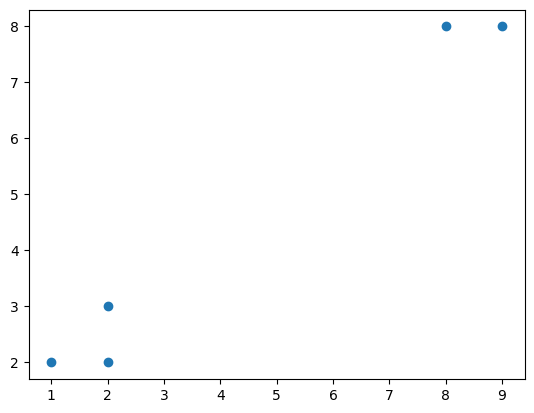

In [59]:
X = np.array([
[1, 2], [2, 2], [2, 3], [8, 8], [9, 8]      
])

plt.scatter(X[:, 0], X[:, 1])

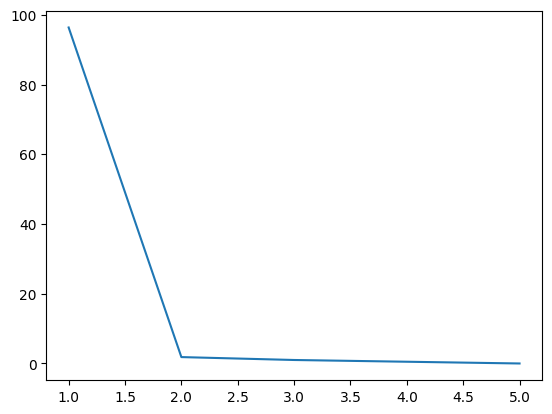

In [60]:
wcss = []
for i in range(1, 6):
    kmeans = KMeans(n_clusters=i, init="k-means++")
    
    kmeans.fit(X)
    
    wcss.append(kmeans.inertia_)
    
    
plt.plot(range(1,6), wcss)

In [61]:
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(X)

In [63]:
silhouette_avg = silhouette_score(X, labels)
sample_silhouette_values = silhouette_samples(X, labels)

print(f"Cluster label: {labels}")
print(f"Silhouette Coeffients for each point: {np.round(sample_silhouette_values, 3)}")
print(f"Average Silhouette score: {round(silhouette_avg, 3)}")

Cluster label: [0 0 0 1 1]
Silhouette Coeffients for each point: [0.874 0.887 0.853 0.882 0.892]
Average Silhouette score: 0.878


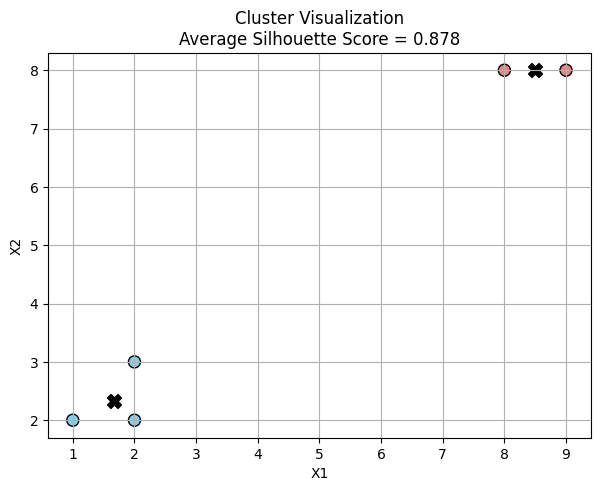

In [85]:
plt.figure(figsize=(7, 5))

colors = ['skyblue' if label == 0 else 'lightcoral' for label in labels]

plt.scatter(X[:, 0], X[:, 1], c=colors, s=75, edgecolors='k')
centeroids = kmeans.cluster_centers_
plt.scatter(centeroids[:, 0], centeroids[:, 1], c="black", marker="X", s=100)

plt.title(f"Cluster Visualization\nAverage Silhouette Score = {silhouette_avg:.3f}")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True)